In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
# import networkx as nx
import matplotlib
import scipy as sp
import sys
sys.path.insert(1, '../')
import util

from scipy.stats import qmc
from numpy.random import Generator, PCG64
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
# from mpl_toolkits.basemap import Basemap
import matplotlib as mpl
# import tqdm
from pathlib import Path
from scipy.signal import argrelextrema
# import seaborn as sns

def stat_dist_theory_res(D,*data):
    A,q_c,q_r = data
    x_pos = np.dot(np.transpose(np.where(A>=0,A,0)),D)
    x_neg = np.dot(np.transpose(np.where(A<0,-A,0)),D)
    # out = np.zeros(len(D))
    # for i in range(len(D)):
    #     out[i] = D[i] - (1+x_pos[i])*q_c[i]/((1+x_pos)*q_c[i] + (1+x_neg)*q_r[i])
    out = D - (1+x_pos)*q_c/((1+x_pos)*q_c + (1+x_neg)*q_r)
    return out

In [136]:
%run DataProcessingTE.py
# Outputs the following:
    # df_AM22 - processed individual TE data from Armstrong McKay et al 2022
    # df_W24 - TE-TE interactions from Wunderling et al 2024
    # df_SSPs - global mean surface temp. anomalies vs pre-industrial (1850-1900). Historical and several SSPs
        # See scenarios for the list of scenarios 

# Loading pre-saved interaction matrices
A = [np.loadtxt("../Data/Simulations/TE/Interaction matrices/A_%s.csv"%r) for r in range(500)]

# (re)-calculating sigmoid betas with value at T_min of 0.001 (i.e. 0.1%)
betas = []
value_at_min=0.001
for x in df_AM22[['Threshold (°C) - Min.','Threshold (°C) - Est.','Threshold (°C) - Max.']].values:
    betas.append(float(sigmoid_beta(x[0],x[1],x[2],value_at_min=value_at_min)))
df_AM22['Sigmoid Beta'] = betas
Tmin = df_AM22.loc['ENSO']['Threshold (°C) - Min.']
Tmax = df_AM22.loc['ENSO']['Threshold (°C) - Max.']
df_AM22.loc['ENSO','Sigmoid Beta'] = np.log(1/value_at_min - 1)/(np.mean([Tmin,Tmax])-Tmin)
betas = df_AM22['Sigmoid Beta'].to_numpy() # important to turn into numpy array for computational speed!!

q_c = 1/(df_AM22['CollapseTime'].to_numpy()+1) # collapse leverage
T_lim = np.array(df_AM22['T_lim'].to_list()) # tipping thresholds
p_r = 1/(10*df_AM22['CollapseTime'].to_numpy()+1) # recovery probabilities: $\tau_{r,i} = 10\tau_{c,i}$

## Impacts
tempimpacts = df_AM22['Max. Impact** (°C) - Global'].to_dict()
# Manually translating the excel entries into numbers
tempimpacts['AMAZ'] = 0.2 # 0.1 at partial dieback, 0.2 at total
tempimpacts['ENSO'] = 0 # NA
tempimpacts['PERM'] = 0.3 # the range is 0.2-0.4
tempimpacts['REEF'] = 0
tempimpacts['WAM'] = 0

df_AM22['DegradedImpact'] = tempimpacts
D_to_T = df_AM22['DegradedImpact'].to_numpy()

/home/jbara/Documents/Code/test-env/Notebooks/DataProcessingTE.py:21: RuntimeWarning: Mean of empty slice
  return np.exp(np.nanmean(np.log([minstr,maxstr])))


In [4]:
df_AM22['Sigmoid Beta']

AMAZ     4.604503
AMOC     2.656444
ASI      3.837086
ENSO     4.604503
GIS      9.866793
PERM     6.906755
REEF    13.813510
WAIS    13.813510
WAM      8.633443
Name: Sigmoid Beta, dtype: float64

In [137]:
df = pd.read_excel('../Data/AR6WG1Fig440_tempseries (1).xlsx')
scenarios = df['scenario'].unique()

dfs = {s: df[df['scenario']==s].set_index('quantile').iloc[:,9:].transpose() for s in scenarios}

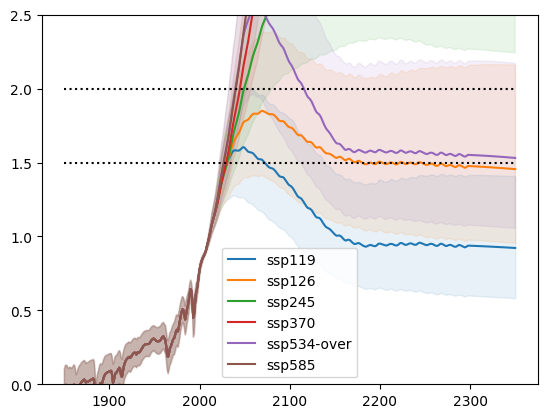

In [92]:
prop_cycle = plt.rcParams['axes.prop_cycle']
colors = prop_cycle.by_key()['color']
for i,s in enumerate(scenarios):
    years = np.arange(1850,2351)
    plt.fill_between(years, dfs[s][0.05],dfs[s][0.95],alpha=0.1,color=colors[i])
    plt.plot(years,dfs[s]['mean'].to_numpy(),label = s,color=colors[i])

plt.plot([1850,2350],[1.5]*2,'k:')
plt.plot([1850,2350],[2]*2,'k:')
plt.ylim([0,2.5])

plt.legend()

# changing pc's

In [112]:
years = np.arange(1850, 2351) 
len_sample=500
T = len(years)
# GMST_hist = df_SSPs['Historical']['Mean'].to_numpy()

p_c = np.ones((len(scenarios),T,len(df_AM22)))
p_c *= 1/(df_AM22['CollapseTime'].to_numpy()+1)
# for t in range(len(GMST_hist)):
#     p_c[:,t,:] *= logistic(GMST_hist[t],T_lim,betas)
for t in range(T):
    for i,s in enumerate(scenarios):
        p_c[i,t,:] *= logistic(dfs[s]['mean'].to_numpy()[t], T_lim, betas)

In [113]:
D = np.zeros((len(scenarios),len_sample,len(TEs),T))
for r in tqdm.tqdm(range(len_sample)):
    for j in range(len(scenarios)):
        for t in range(1,T):
            D[j,r,:,t] = util.environmental_update(D[j,r,:,t-1],A[r],p_c=p_c[j,t,:],p_r=p_r)

D_noint = np.zeros((len(scenarios),len(TEs),T))
for t in tqdm.tqdm(range(1,T)):
    for j in range(len(scenarios)):
        D_noint[j,:,t] = util.environmental_update(D_noint[j,:,t-1],np.zeros((len(TEs),len(TEs))),p_c=p_c[j,t,:],p_r=p_r)

100%|███████████████████████████████████████| 500/500 [00:00<00:00, 3697.68it/s]


# Saving data

In [114]:
folder= "../Data/Simulations/TE/Sigmoid/rx10c/Extended SSPs/"
Path(folder[:-1]).mkdir(parents=True, exist_ok=True)
# years = 

for i,te in enumerate(TEs):
    # np.savetxt(folder+"D_"+te+"_Historical.csv", D[0,:,i,:len(GMST_hist)])
    # np.savetxt(folder+"D_no_interaction_"+te+"_Historical.csv", D_noint[0,i,:len(GMST_hist)])
    for j in range(len(scenarios)):
        np.savetxt(folder+"D_"+te+"_"+scenarios[j]+".csv", D[j,:,i,:])
        np.savetxt(folder+"D_no_interaction_"+te+"_"+scenarios[j]+".csv", D_noint[j,i,:])

# Visualisation

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import util

In [12]:
folder= "../Data/Simulations/Extended SSPs/"
scenarios = ['ssp119', 'ssp126', 'ssp245', 'ssp370', 'ssp585'] # the manuscript doesn't contain ssp534-over
TEs = ['AMAZ', 'AMOC', 'ASI', 'ENSO', 'GIS', 'PERM', 'REEF', 'WAIS', 'WAM']
# scenarios = ['ssp119', 'ssp126','ssp534-over']
D = np.array([[np.loadtxt(folder+"D_"+te+"_"+scenarios[j]+".csv") 
                     for i,te in enumerate(TEs)] for j in range(len(scenarios))]).transpose((0,2,1,3))
D_noint = np.array([[np.loadtxt(folder+"D_no_interaction_"+te+"_"+scenarios[j]+".csv") 
                     for i,te in enumerate(TEs)] for j in range(len(scenarios))])

folder_out = '../Figures/TE (sigmoid)/rx10c/'

In [12]:
if len(scen_labels) != len(scenarios):
    scen_labels = scenarios
len(scen_labels)

5

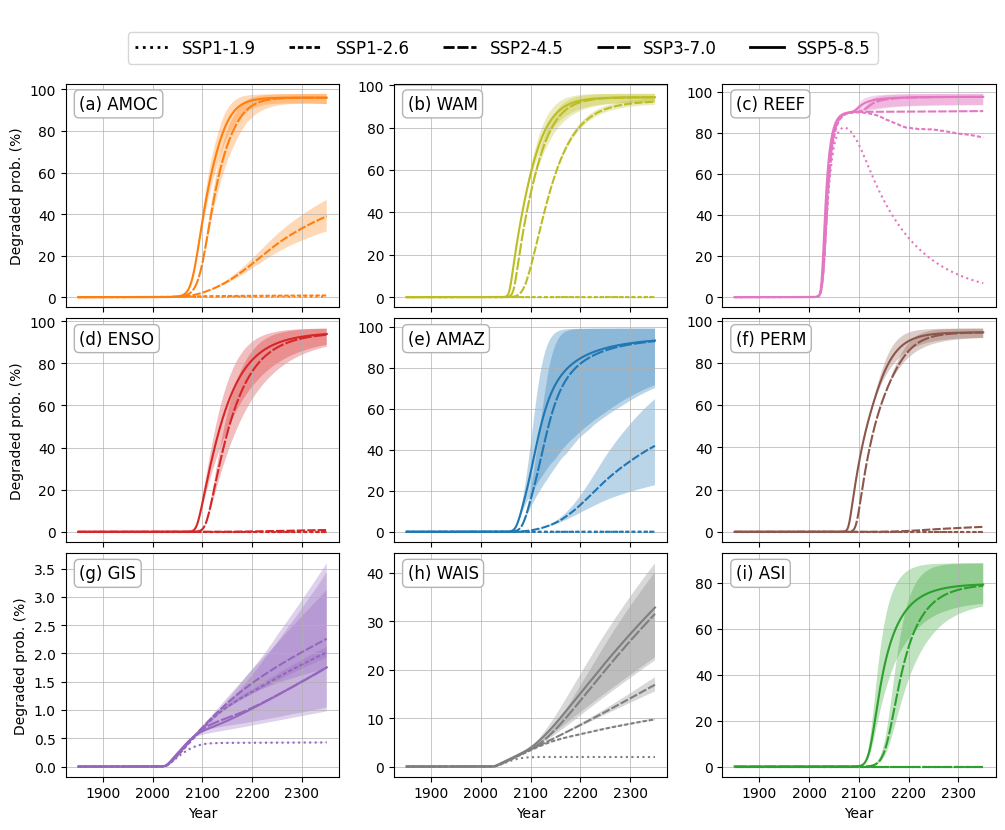

In [13]:
years = np.arange(1850, 2351) 

fig,axs = plt.subplots(figsize=(12,9),nrows=3,ncols=3,sharex=True,sharey=False)
fig.subplots_adjust(hspace=0.05) # hspace=0.05

prop_cycle = plt.rcParams['axes.prop_cycle']
colors = prop_cycle.by_key()['color']
# linestyles = [':',(0, (3, 1, 1, 1, 1, 1)),'-.','--', (2,(10,3)) ,(5,(10,3))]
# scen_labels = ['SSP1-1.9', 'SSP1-2.6', 'SSP2-4.5', 'SSP3-7.0', 'SSP5-3.4-over', 'SSP5-8.5']

# linestyles = [':',(0, (3, 1, 1, 1, 1, 1)),'-.','--',(5,(10,3))]
linestyles = [':'] + [(0,(2*j+2,1)) for j in range(len(scenarios)-2)] + ['-']
scen_labels = ['SSP1-1.9', 'SSP1-2.6', 'SSP2-4.5', 'SSP3-7.0', 'SSP5-8.5']
if len(scen_labels) != len(scenarios):
    scen_labels = scenarios

TE_ordered = ['AMOC', 'WAM', 'REEF',
              'ENSO', 'AMAZ','PERM',
              'GIS', 'WAIS', 'ASI']
letters = ['(%s)'%l for l in 'abcdefghi']
TE_ind = {te:i for i,te in enumerate(TEs)}
for i_ax,te in enumerate(TE_ordered):
    i = TE_ind[te]
    axs[i_ax//3,i_ax%3].annotate(letters[i_ax] + ' '+ TEs[i],(0.05,0.95),
                                 xycoords='axes fraction',ha='left',va='top',fontsize=12,
                                 bbox=dict(fc='white',edgecolor='0.7',boxstyle='round'))
    # axs[i_ax//3,i_ax%3].plot(years[:D_hist.shape[-1]],D_hist[i,:,:].mean(axis=0)*100,
    #                    c=util.lighten_color(colors[i],0.65), 
    #                    ls='-',lw=1)
    axs[i_ax//3,i_ax%3].grid(visible=True,lw=0.5,axis='both')
    for j in range(len(scenarios)):
        axs[i_ax//3,i_ax%3].plot(years,D[j,:,i,:].mean(axis=0)*100,
                                 c=util.lighten_color(colors[i],1),#0.1+(j+3)/(len(scenarios)+3)), 
                                 ls=linestyles[j],
                                 lw=1.5)
        # axs[i_ax//3,i_ax%3].plot(years,D_noint[j,i,:]*100,color='k',lw=0.5)
        # axs[i_ax//3,i_ax%3].plot(years,D[j,:,i,:].mean(axis=0)*100,
        #                          c=colors[i], ls=linestyles[j],
        #                          lw=1)
        axs[i_ax//3,i_ax%3].fill_between(years,
                                         np.quantile(D[j,:,i,:],0.05,axis=0)*100,
                                         np.quantile(D[j,:,i,:],0.95,axis=0)*100,
                                         color=util.lighten_color(colors[i],1),#0.1+(j+3)/(len(scenarios)+3)), 
                                         alpha=0.3,
                                         lw=1,edgecolor='none')

# lines=[Line2D([0], [0], color='k', lw=2, label='Historical')] 
lines = [Line2D([0], [0], color=util.lighten_color('k',1),#0.1+(j+3)/(len(scenarios)+3)), 
                lw=2, 
                label=scen_labels[j], 
                ls = linestyles[j]) 
         for j in range(len(scenarios))]

for i in range(3):
    axs[-1,i].set_xlabel('Year')
    axs[i,0].set_ylabel('Degraded prob. (%)')

fig.legend(handles=lines,ncols=len(scenarios),loc='upper center',
           prop={'size':12},borderaxespad=2)
# fig.savefig(folder_out+'extendedSSPs.pdf',format='pdf',dpi=300,bbox_inches='tight')

In [95]:
scenarios

['ssp119', 'ssp126', 'ssp245', 'ssp370', 'ssp585']

In [99]:
TEs
D[0,:,-1,np.where(years==2350)[0][0]].mean(axis=0)*100

0.0014511060099569723

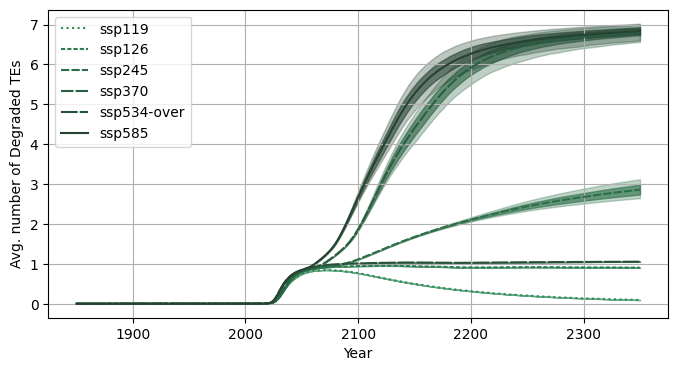

In [49]:
fig,ax = plt.subplots(figsize=(8,4))
theme_col = 'k'
colors = sns.dark_palette("seagreen",len(scenarios)+2)[::-1]
linestyles = [':'] + [(0,(2*j+2,1)) for j in range(len(scenarios)-2)] + ['-']
scen_labels = ['SSP1-1.9', 'SSP1-2.6', 'SSP2-4.5', 'SSP3-7.0', 'SSP5-8.5']
if len(scen_labels) != len(scenarios):
    scen_labels = scenarios
years=np.arange(1850,2351)
for j in range(len(scenarios)):
    ax.plot(years,D[j,:,:,:].sum(axis=1).mean(axis=0),
        color=util.lighten_color(colors[j],1),label=scen_labels[j],ls=linestyles[j])
    ax.fill_between(years, 
                    np.quantile(D[j,:,:,:].sum(axis=1),0.05,axis=0),
                    np.quantile(D[j,:,:,:].sum(axis=1),0.95,axis=0),
                    # lighten_color by 0.3
                    color=util.lighten_color(colors[j],1),
                    edgecolor=util.lighten_color(colors[j],1), 
                    alpha=0.3)
    ax.fill_between(years, 
                 np.quantile(D[j,:,:,:].sum(axis=1),0.25,axis=0),
                 np.quantile(D[j,:,:,:].sum(axis=1),0.75,axis=0),
                    # lighten_color by 0.65
                 color=util.lighten_color(colors[j],1),
                 edgecolor=util.lighten_color(colors[j],1),
                 alpha=0.6)
    # ax.plot(years,D_noint[j,:,:].sum(axis=0),
    #                          c=util.lighten_color(colors[j],1), 
    #                          ls='--',lw=1)

ax.grid()
# ax.set_xlim([1850,2350])
ax.set_ylabel('Avg. number of Degraded TEs')
ax.set_xlabel('Year')

# ax_temp = ax.inset_axes([1850, 1, 170, 3.5], transform=ax.transData)
# ax_temp.yaxis.tick_right()
# ax_temp.set_xlim([1850,2350])
# ax_temp.set_xticks([1900,2100,2300])
# ax_temp.tick_params(axis='both', which='major', labelsize=8)
# for j,s in enumerate(scenarios):
#     # ax_temp.fill_between(years, dfs[s][0.05],dfs[s][0.95],alpha=0.1,color=colors[i])
#     ax_temp.plot(years,dfs[s]['mean'].to_numpy(), color=colors[j])

legend=plt.legend(loc='upper left',ncols=1)
# fig.savefig(folder_out+'ES_extendedSSPs.pdf',format='pdf',dpi=300,bbox_inches='tight')

# histograms

In [13]:
scenarios

['ssp119', 'ssp126', 'ssp245', 'ssp370', 'ssp585']

In [35]:
D.shape

(5, 500, 9, 501)

In [40]:
data.shape

(4500, 5)

(array([6., 0., 2., 0., 0., 0., 0., 0., 0., 1.]),
 array([1. , 1.4, 1.8, 2.2, 2.6, 3. , 3.4, 3.8, 4.2, 4.6, 5. ]),
 <BarContainer object of 10 artists>)

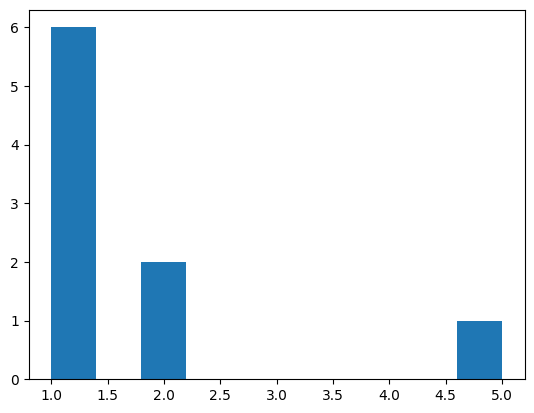

In [58]:
eval_year = 2100
data = np.reshape(D[:,:,:,np.where(years==eval_year)[0][0]], (5,500*9), order='C').transpose()*100 #D[:,:,:,np.where(years==eval_year)[0][0]].mean(axis=1).transpose()*100 
bins = [0,10,33,66,90,100]#[0,1,10,33,66,90,99,100] # IPCC likelihood terms
# terms = ['Exceptionally unlikely', 'Very unlikely', 'Unlikely', 'About as likely as not', 'Likely', 'Very likely', 'Virtually certain']
# inds = np.digitize(data, bins)
# plt.hist(D[:,:,:,-1].mean(axis=1).transpose()*100,
#         # np.reshape(D[:,:,:,-1], (5,500*9), order='C').transpose()*100, 
#          # [0,1,10,33,66,90,99,100],
#          label=scenarios)
# plt.legend()
# plt.hist(inds,align='mid',label=scenarios,rwidth=1)
# plt.hist(data,density=True)
# for i in range(5):
# sns.kdeplot(data={s:data[:,i] for i,s in enumerate(scenarios)},clip=[0,100])
plt.hist(inds[:,1],align='mid',rwidth=1)
# plt.legend()

In [66]:
data.shape

(5, 500, 501)

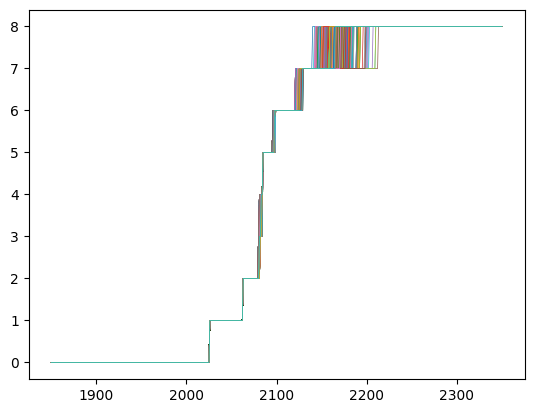

In [87]:
data = (D>=0.1).sum(axis=2)
# for i in range(5):
#     # plt.plot(years,data[i,:,:].mean(axis=0),label=scenarios[i],color=colors[i])
#     plt.scatter(years,data[i,:,:].mean(axis=0),label=scenarios[i],color=colors[i],s=1)
    # plt.errorbar(years, data[i,:,:].mean(axis=0),
    #                 yerr=(np.abs(np.quantile(data[i,:,:],0.05,axis=0)-data[i,:,:].mean(axis=0)),
    #                 np.abs(np.quantile(data[i,:,:],0.95,axis=0)-data[i,:,:].mean(axis=0))),
    #                 # lighten_color by 0.3
    #                 color=util.lighten_color(colors[i],1))
    # plt.errorbar(years, data[i,:,:].mean(axis=0),
    #              yerr=(np.quantile(data[i,:,:],0.25,axis=0)-data[i,:,:].mean(axis=0),
    #              np.quantile(data[i,:,:],0.75,axis=0)-data[i,:,:].mean(axis=0)),
    #                 # lighten_color by 0.65
    #              color=util.lighten_color(colors[i],1))

for i in range(500):
    plt.plot(years,data[4,i,:],lw=0.5)

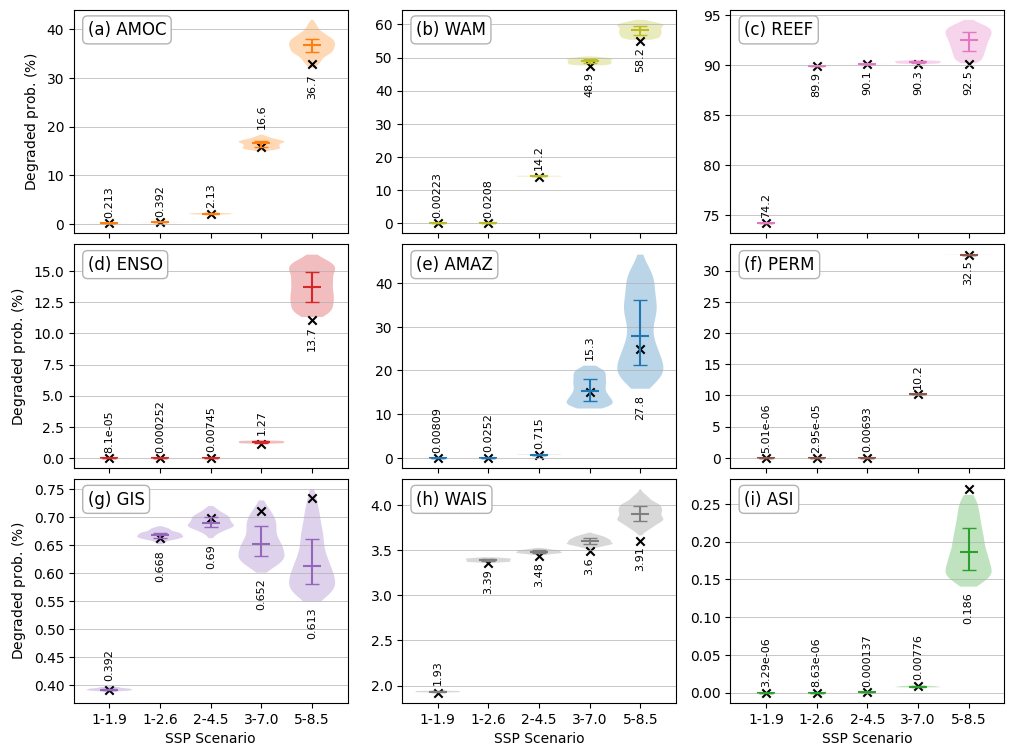

In [40]:
TE_ordered = ['AMOC', 'WAM', 'REEF',
              'ENSO', 'AMAZ','PERM',
              'GIS', 'WAIS', 'ASI']
letters = ['(%s)'%l for l in 'abcdefghi']
TE_ind = {te:i for i,te in enumerate(TEs)}

fig,axs = plt.subplots(figsize=(12,9),nrows=3,ncols=3,sharex=True,sharey=False)
# axs[0,0].set_yscale('log')
fig.subplots_adjust(hspace=0.05)

prop_cycle = plt.rcParams['axes.prop_cycle']
colors = prop_cycle.by_key()['color']
linestyles = [':'] + [(0,(2*j+2,1)) for j in range(len(scenarios)-2)] + ['-']
scen_labels = ['SSP1-1.9', 'SSP1-2.6', 'SSP2-4.5', 'SSP3-7.0', 'SSP5-8.5']

evaluate_years = [2100]#,2350]#[2100,2350]
no_years = len(evaluate_years)
stacked=True
for i_ax,te in enumerate(TE_ordered):
    i = TE_ind[te]    
    # data = [D[j,:,i,[np.where(years==y) for y in evaluate_years]]*100 for j in range(len(scenarios))]
    data = D[:,:,i,[np.where(years==y) for y in evaluate_years]]*100
    for j in range(len(scenarios)):
        # parts.append(axs[i_ax//3,i_ax%3].violinplot(data[j,:,:,0,0],showmeans=False, showmedians=False,
        #                                             showextrema=False, widths=0.7))
        if stacked or no_years==1:
            pos = [j+1]*no_years
        else:
            pos = np.linspace(j+1,j + 2-1/no_years,num=no_years)-0.5/no_years
        vp = axs[i_ax//3,i_ax%3].violinplot(data[j,:,:,0,0],showmeans=False, showmedians=False,
                                            showextrema=False, widths=1/(no_years+0.1),
                                            positions=pos)
        for pc in vp['bodies']:
            pc.set_facecolor(util.lighten_color(colors[i],1))
            # pc.set_edgecolor('k')
    axs[i_ax//3,i_ax%3].annotate(letters[i_ax] + ' '+TEs[i],(0.05,0.95),xycoords='axes fraction',
                                 ha='left',va='top',fontsize=12,
                                 bbox=dict(fc='white',edgecolor='0.7',boxstyle='round'))
    for j,yr in enumerate(evaluate_years):
        if stacked or no_years==1:
            x=np.arange(1,6)
        else:
            x= np.arange(1,6)+(j-0.5)/no_years
        axs[i_ax//3,i_ax%3].scatter(x,(100*D_noint[:,i,np.where(years==yr)[0][0]]),
                                    marker='x',color='k')
        y= np.median(data[:,:,j,0,0],axis=1)
        yerr = np.abs(np.quantile(data[:,:,j,0,0],[0.25,0.75],axis=1)-y)
        axs[i_ax//3,i_ax%3].scatter(x,y,
                                    color=util.lighten_color(colors[i],1),
                                    marker='_',s=150)
        axs[i_ax//3,i_ax%3].errorbar(x,y,yerr=yerr,ls='',
                                     c=util.lighten_color(colors[i],1),
                                     marker='',barsabove=True,capsize=5)
    
    
    # axs[i_ax//3,i_ax%3].set_yscale('log')
    axs[i_ax//3,i_ax%3].grid(visible=True,lw=0.5,axis='y')

    ylim=axs[i_ax//3,i_ax%3].get_ylim()
    for s in range(5):
        # str_to_print = '%.3g'%(y[s])
        # if len(str_to_print) > 5:
        #     rot=90
        # axs[i_ax//3,i_ax%3].annotate('%.3g'%(y[s]),
        #                              [s+0.6,y[s]],
        #                              ha='left',va='bottom',fontsize=8,rotation=-90)
        if data[s].mean() <= ylim[0] + 0.5*(ylim[1]-ylim[0]): #max()<= 0.9*np.max(ylim):
            axs[i_ax//3,i_ax%3].annotate('%.3g'%(y[s]),
                                   [s+1,
                                    max(data[s].max(),  
                                        100*D_noint[:,i,np.where(years==yr)[0][0]][s])+0.025*(ylim[1]-ylim[0])],
                                   ha='center',va='bottom',fontsize=8,rotation=90)
        else:
            axs[i_ax//3,i_ax%3].annotate('%.3g'%(y[s]),
                                   [s+1,
                                    min(data[s].min(), 
                                        100*D_noint[:,i,np.where(years==yr)[0][0]][s])-0.025*(ylim[1]-ylim[0])],
                                   ha='center',va='top',fontsize=8,rotation=90)

for i in range(3):
    axs[-1,i].set_xlabel('SSP Scenario')
    axs[i,0].set_ylabel(r'Degraded prob. $(\%)$')

xlim = axs[0,0].get_xlim()
axs[0,0].set_xticks(range(1,6),[s[3:] for s in scen_labels])
axs[0,0].set_xlim(xlim)

folder_out = '../Figures/'
fig.savefig(folder_out+'SSPs_'+str(evaluate_years[0])+'.pdf',format='pdf',bbox_inches='tight',dpi=300)

In [35]:
ylim

(np.float64(-0.01345213957544328), np.float64(0.2825671255214348))

In [16]:
'%.3g'%(y[s])

'0.186'

In [218]:
TEs

['AMAZ', 'AMOC', 'ASI', 'ENSO', 'GIS', 'PERM', 'REEF', 'WAIS', 'WAM']

In [236]:
D.shape

(5, 500, 9, 501)

# fig s2

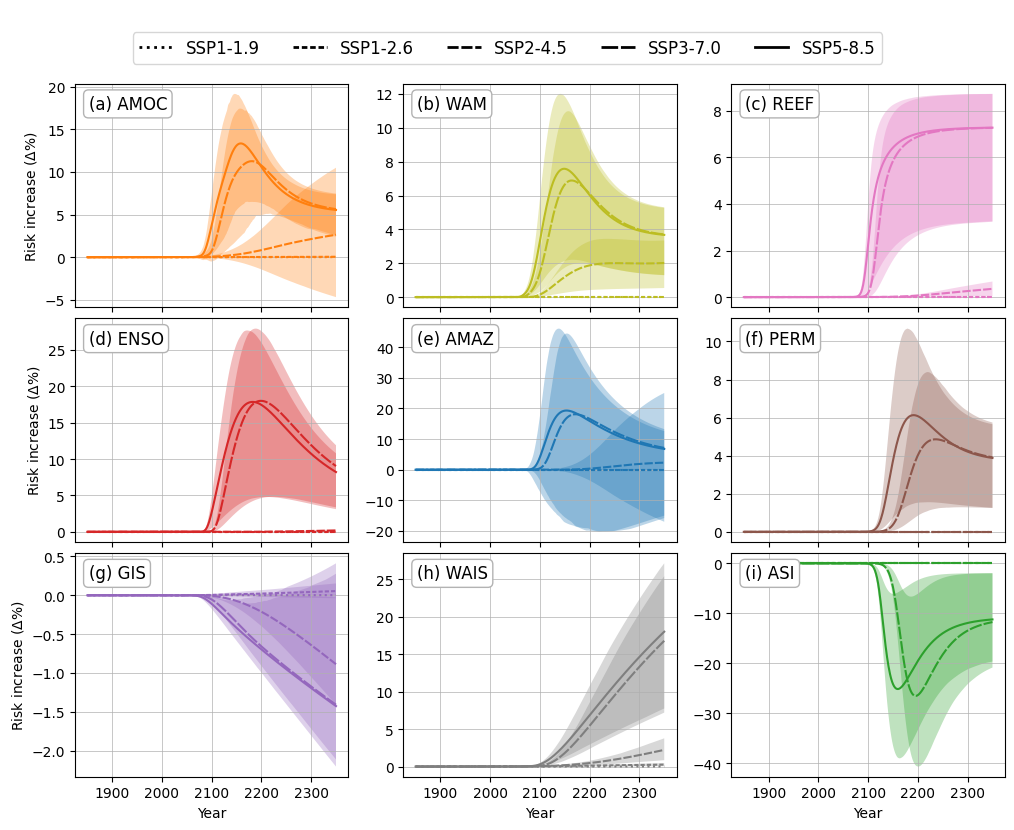

In [142]:
years = np.arange(1850, 2351) 

fig,axs = plt.subplots(figsize=(12,9),nrows=3,ncols=3,sharex=True,sharey=False)
fig.subplots_adjust(hspace=0.05) # hspace=0.05

prop_cycle = plt.rcParams['axes.prop_cycle']
colors = prop_cycle.by_key()['color']
# linestyles = [':',(0, (3, 1, 1, 1, 1, 1)),'-.','--', (2,(10,3)) ,(5,(10,3))]
# scen_labels = ['SSP1-1.9', 'SSP1-2.6', 'SSP2-4.5', 'SSP3-7.0', 'SSP5-3.4-over', 'SSP5-8.5']

# linestyles = [':',(0, (3, 1, 1, 1, 1, 1)),'-.','--',(5,(10,3))]
linestyles = [':'] + [(0,(2*j+2,1)) for j in range(len(scenarios)-2)] + ['-']
scen_labels = ['SSP1-1.9', 'SSP1-2.6', 'SSP2-4.5', 'SSP3-7.0', 'SSP5-8.5']
if len(scen_labels) != len(scenarios):
    scen_labels = scenarios

TE_ordered = ['AMOC', 'WAM', 'REEF',
              'ENSO', 'AMAZ','PERM',
              'GIS', 'WAIS', 'ASI']
letters = ['(%s)'%l for l in 'abcdefghi']
TE_ind = {te:i for i,te in enumerate(TEs)}
for i_ax,te in enumerate(TE_ordered):
    i = TE_ind[te]
    axs[i_ax//3,i_ax%3].annotate(letters[i_ax] + ' '+ TEs[i],(0.05,0.95),
                                 xycoords='axes fraction',ha='left',va='top',fontsize=12,
                                 bbox=dict(fc='white',edgecolor='0.7',boxstyle='round'))
    axs[i_ax//3,i_ax%3].grid(visible=True,lw=0.5,axis='both')
    for j in range(len(scenarios)):
        axs[i_ax//3,i_ax%3].plot(years,(D[j,:,i,:].mean(axis=0)-D_noint[j,i,:])*100,
                                 c=util.lighten_color(colors[i],1),#0.1+(j+3)/(len(scenarios)+3)), 
                                 ls=linestyles[j],
                                 lw=1.5)
        axs[i_ax//3,i_ax%3].fill_between(years,
                                         (np.quantile(D[j,:,i,:],0.05,axis=0) -D_noint[j,i,:])*100,
                                         (np.quantile(D[j,:,i,:],0.95,axis=0) -D_noint[j,i,:])*100,
                                         color=util.lighten_color(colors[i],1),#0.1+(j+3)/(len(scenarios)+3)), 
                                         alpha=0.3,
                                         lw=1,edgecolor='none')
        
lines = [Line2D([0], [0], color=util.lighten_color('k',1),#0.1+(j+3)/(len(scenarios)+3)), 
                lw=2, 
                label=scen_labels[j], 
                ls = linestyles[j]) 
         for j in range(len(scenarios))]

for i in range(3):
    axs[-1,i].set_xlabel('Year')
    axs[i,0].set_ylabel(r'Risk increase ($\Delta \%$)')

fig.legend(handles=lines,ncols=len(scenarios),loc='upper center',
           prop={'size':12},borderaxespad=2)
fig.savefig(folder_out+'extendedSSPs_int_diff.pdf',format='pdf',dpi=300,bbox_inches='tight')

In [145]:
print(np.linspace(j+1,j + 2-1/no_years,num=no_years)-0.5/no_years)

[1.75 2.25]


## relative increase from interactions

/tmp/ipykernel_36261/83141886.py:29: RuntimeWarning: invalid value encountered in divide
  axs[i_ax//3,i_ax%3].plot(years,(D[j,:,i,:].mean(axis=0)-D_noint[j,i,:])*100/D_noint[j,i,:],
/tmp/ipykernel_36261/83141886.py:34: RuntimeWarning: invalid value encountered in divide
  (np.quantile(D[j,:,i,:],0.05,axis=0) -D_noint[j,i,:])*100/D_noint[j,i,:],
/tmp/ipykernel_36261/83141886.py:35: RuntimeWarning: invalid value encountered in divide
  (np.quantile(D[j,:,i,:],0.95,axis=0) -D_noint[j,i,:])*100/D_noint[j,i,:],


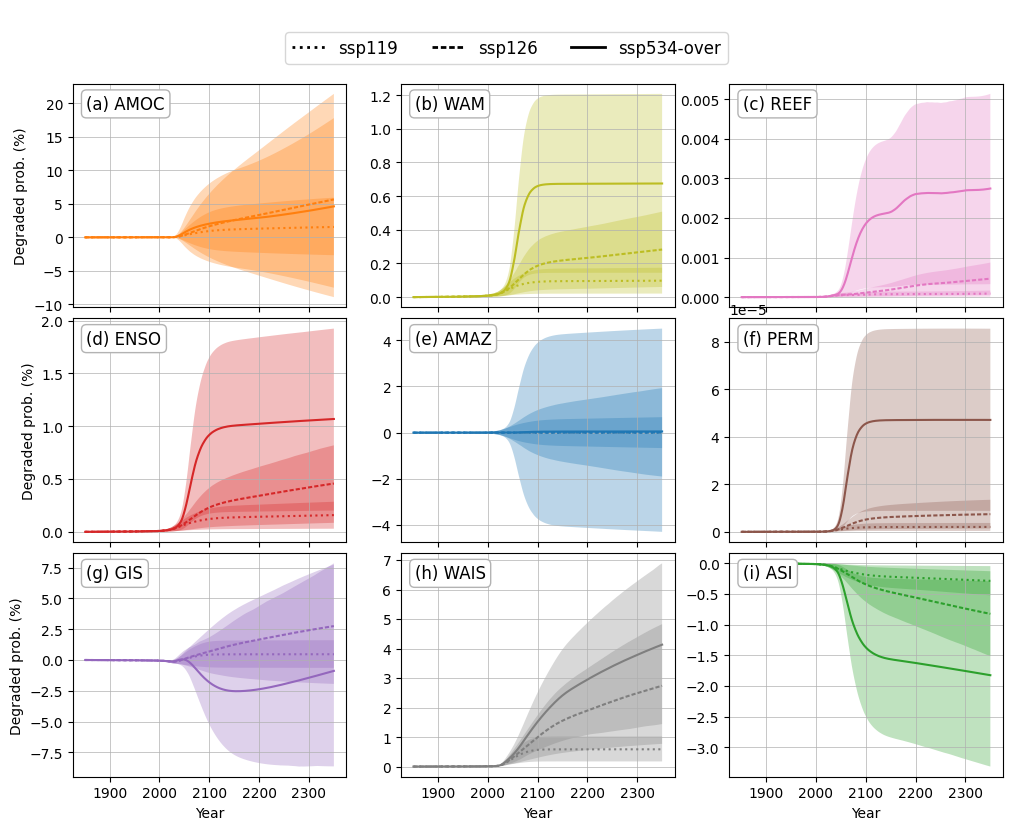

In [27]:
years = np.arange(1850, 2351) 

fig,axs = plt.subplots(figsize=(12,9),nrows=3,ncols=3,sharex=True,sharey=False)
fig.subplots_adjust(hspace=0.05) # hspace=0.05

prop_cycle = plt.rcParams['axes.prop_cycle']
colors = prop_cycle.by_key()['color']
# linestyles = [':',(0, (3, 1, 1, 1, 1, 1)),'-.','--', (2,(10,3)) ,(5,(10,3))]
# scen_labels = ['SSP1-1.9', 'SSP1-2.6', 'SSP2-4.5', 'SSP3-7.0', 'SSP5-3.4-over', 'SSP5-8.5']

# linestyles = [':',(0, (3, 1, 1, 1, 1, 1)),'-.','--',(5,(10,3))]
linestyles = [':'] + [(0,(2*j+2,1)) for j in range(len(scenarios)-2)] + ['-']
scen_labels = ['SSP1-1.9', 'SSP1-2.6', 'SSP2-4.5', 'SSP3-7.0', 'SSP5-8.5']
if len(scen_labels) != len(scenarios):
    scen_labels = scenarios

TE_ordered = ['AMOC', 'WAM', 'REEF',
              'ENSO', 'AMAZ','PERM',
              'GIS', 'WAIS', 'ASI']
letters = ['(%s)'%l for l in 'abcdefghi']
TE_ind = {te:i for i,te in enumerate(TEs)}
for i_ax,te in enumerate(TE_ordered):
    i = TE_ind[te]
    axs[i_ax//3,i_ax%3].annotate(letters[i_ax] + ' '+ TEs[i],(0.05,0.95),
                                 xycoords='axes fraction',ha='left',va='top',fontsize=12,
                                 bbox=dict(fc='white',edgecolor='0.7',boxstyle='round'))
    axs[i_ax//3,i_ax%3].grid(visible=True,lw=0.5,axis='both')
    for j in range(len(scenarios)):
        axs[i_ax//3,i_ax%3].plot(years,(D[j,:,i,:].mean(axis=0)-D_noint[j,i,:])*100/D_noint[j,i,:],
                                 c=util.lighten_color(colors[i],1),#0.1+(j+3)/(len(scenarios)+3)), 
                                 ls=linestyles[j],
                                 lw=1.5)
        axs[i_ax//3,i_ax%3].fill_between(years,
                                         (np.quantile(D[j,:,i,:],0.05,axis=0) -D_noint[j,i,:])*100/D_noint[j,i,:],
                                         (np.quantile(D[j,:,i,:],0.95,axis=0) -D_noint[j,i,:])*100/D_noint[j,i,:],
                                         color=util.lighten_color(colors[i],1),#0.1+(j+3)/(len(scenarios)+3)), 
                                         alpha=0.3,
                                         lw=1,edgecolor='none')
        
lines = [Line2D([0], [0], color=util.lighten_color('k',1),#0.1+(j+3)/(len(scenarios)+3)), 
                lw=2, 
                label=scen_labels[j], 
                ls = linestyles[j]) 
         for j in range(len(scenarios))]

for i in range(3):
    axs[-1,i].set_xlabel('Year')
    axs[i,0].set_ylabel('Degraded prob. (%)')

fig.legend(handles=lines,ncols=len(scenarios),loc='upper center',
           prop={'size':12},borderaxespad=2)
# fig.savefig(folder_out+'extendedSSPs_int_diff.pdf',format='pdf',dpi=300,bbox_inches='tight')

### temp vs risk

In [252]:
scenarios = ['ssp119', 'ssp126', 'ssp245', 'ssp370', 'ssp585']
df = pd.read_excel('../Data/AR6WG1Fig440_tempseries (1).xlsx')

dfs = {s: df[df['scenario']==s].set_index('quantile').iloc[:,9:].transpose() for s in scenarios}

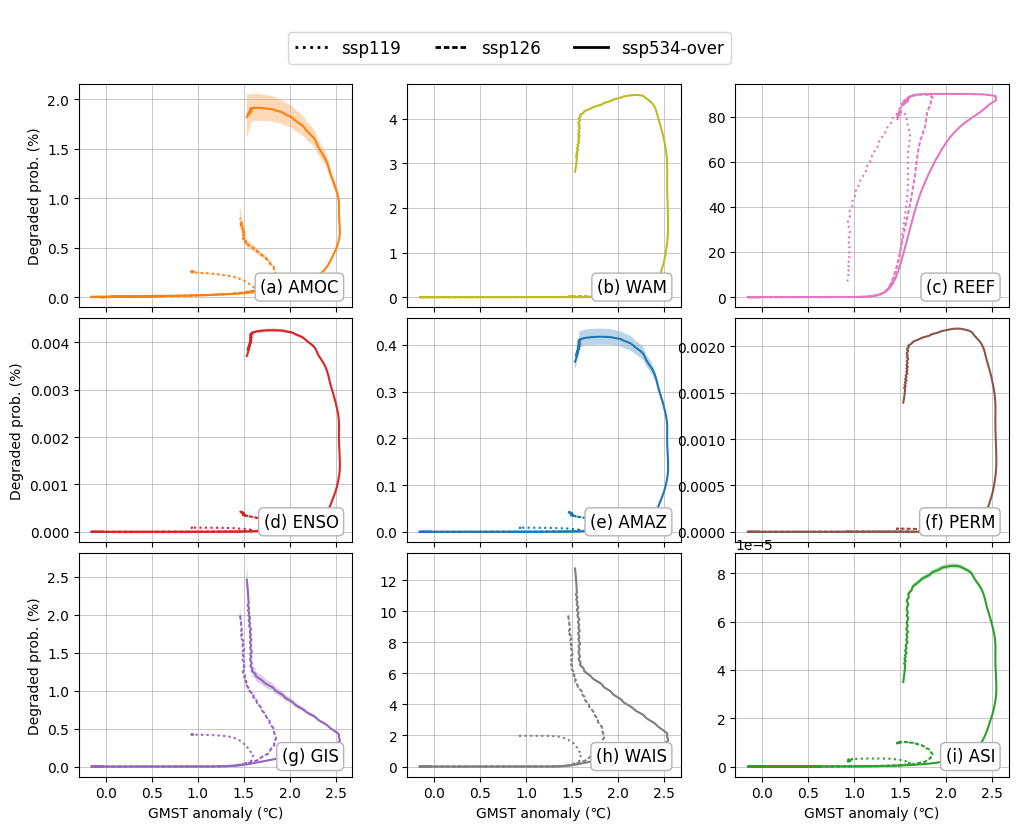

In [25]:
years = np.arange(1850, 2351) 

fig,axs = plt.subplots(figsize=(12,9),nrows=3,ncols=3,sharex=True,sharey=False)
fig.subplots_adjust(hspace=0.05) # hspace=0.05

prop_cycle = plt.rcParams['axes.prop_cycle']
colors = prop_cycle.by_key()['color']
# linestyles = [':',(0, (3, 1, 1, 1, 1, 1)),'-.','--', (2,(10,3)) ,(5,(10,3))]
# scen_labels = ['SSP1-1.9', 'SSP1-2.6', 'SSP2-4.5', 'SSP3-7.0', 'SSP5-3.4-over', 'SSP5-8.5']

# linestyles = [':',(0, (3, 1, 1, 1, 1, 1)),'-.','--',(5,(10,3))]
linestyles = [':'] + [(0,(2*j+2,1)) for j in range(len(scenarios)-2)] + ['-']
scen_labels = ['SSP1-1.9', 'SSP1-2.6', 'SSP2-4.5', 'SSP3-7.0', 'SSP5-8.5']
if len(scen_labels) != len(scenarios):
    scen_labels = scenarios

TE_ordered = ['AMOC', 'WAM', 'REEF',
              'ENSO', 'AMAZ','PERM',
              'GIS', 'WAIS', 'ASI']
letters = ['(%s)'%l for l in 'abcdefghi']
TE_ind = {te:i for i,te in enumerate(TEs)}
for i_ax,te in enumerate(TE_ordered):
    i = TE_ind[te]
    axs[i_ax//3,i_ax%3].annotate(letters[i_ax] + ' '+ TEs[i],(0.95,0.05),
                                 xycoords='axes fraction',ha='right',va='bottom',fontsize=12,
                                 bbox=dict(fc='white',edgecolor='0.7',boxstyle='round'))
    # axs[i_ax//3,i_ax%3].plot(years[:D_hist.shape[-1]],D_hist[i,:,:].mean(axis=0)*100,
    #                    c=util.lighten_color(colors[i],0.65), 
    #                    ls='-',lw=1)
    axs[i_ax//3,i_ax%3].grid(visible=True,lw=0.5,axis='both')
    # axs[i_ax//3,i_ax%3].set_yscale('log')
    # axs[i_ax//3,i_ax%3].set_xscale('log')
    for j in range(len(scenarios)):
        axs[i_ax//3,i_ax%3].plot(dfs[scenarios[j]]['mean'].to_numpy(),D[j,:,i,:].mean(axis=0)*100,
                                 c=util.lighten_color(colors[i],1),#0.1+(j+3)/(len(scenarios)+3)), 
                                 ls=linestyles[j],
                                 lw=1.5)
        # axs[i_ax//3,i_ax%3].scatter(dfs[scenarios[j]]['mean'].to_numpy(),D[j,:,i,:].mean(axis=0)*100,
        #                          color=util.lighten_color(colors[i],1),#0.1+(j+3)/(len(scenarios)+3)), 
        #                          marker='x',s=0.5)
        # axs[i_ax//3,i_ax%3].plot(years,D[j,:,i,:].mean(axis=0)*100,
        #                          c=colors[i], ls=linestyles[j],
        #                          lw=1)
        axs[i_ax//3,i_ax%3].fill_between(dfs[scenarios[j]]['mean'].to_numpy(),
                                         np.quantile(D[j,:,i,:],0.05,axis=0)*100,
                                         np.quantile(D[j,:,i,:],0.95,axis=0)*100,
                                         color=util.lighten_color(colors[i],1),#0.1+(j+3)/(len(scenarios)+3)), 
                                         alpha=0.3,
                                         lw=1,edgecolor='none')

# lines=[Line2D([0], [0], color='k', lw=2, label='Historical')] 
lines = [Line2D([0], [0], color=util.lighten_color('k',1),#0.1+(j+3)/(len(scenarios)+3)), 
                lw=2, 
                label=scen_labels[j], 
                ls = linestyles[j]) 
         for j in range(len(scenarios))]

for i in range(3):
    axs[-1,i].set_xlabel('GMST anomaly (℃)')
    axs[i,0].set_ylabel('Degraded prob. (%)')

fig.legend(handles=lines,ncols=5,loc='upper center',
           prop={'size':12},borderaxespad=2)

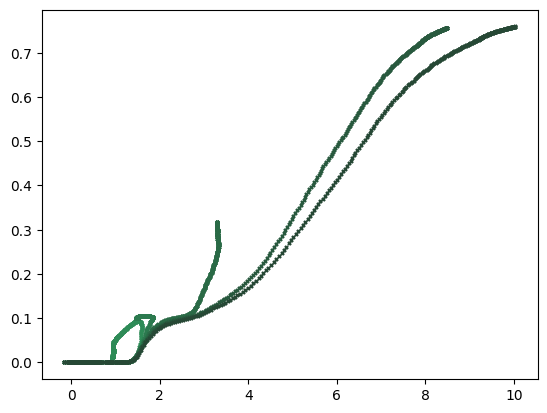

In [129]:
for j,s in enumerate(scenarios):
    plt.scatter(dfs[s]['mean'].to_numpy(),
                D[j,:,:,:].mean(axis=1).mean(axis=0),
                color=colors[j],marker='x',s=5)

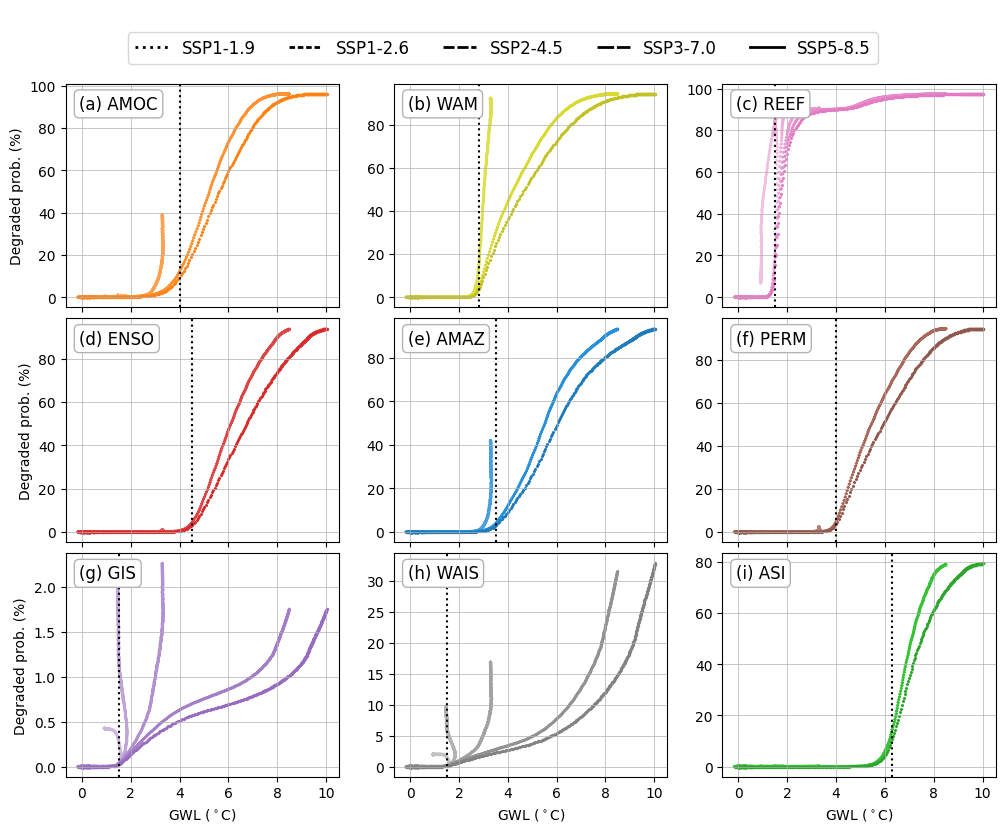

In [143]:
years = np.arange(1850, 2351) 

fig,axs = plt.subplots(figsize=(12,9),nrows=3,ncols=3,sharex=True,sharey=False)
fig.subplots_adjust(hspace=0.05) # hspace=0.05

prop_cycle = plt.rcParams['axes.prop_cycle']
colors = prop_cycle.by_key()['color']
# linestyles = [':',(0, (3, 1, 1, 1, 1, 1)),'-.','--', (2,(10,3)) ,(5,(10,3))]
# scen_labels = ['SSP1-1.9', 'SSP1-2.6', 'SSP2-4.5', 'SSP3-7.0', 'SSP5-3.4-over', 'SSP5-8.5']

# linestyles = [':',(0, (3, 1, 1, 1, 1, 1)),'-.','--',(5,(10,3))]
linestyles = [':'] + [(0,(2*j+2,1)) for j in range(len(scenarios)-2)] + ['-']
scen_labels = ['SSP1-1.9', 'SSP1-2.6', 'SSP2-4.5', 'SSP3-7.0', 'SSP5-8.5']

TE_ordered = ['AMOC', 'WAM', 'REEF',
              'ENSO', 'AMAZ','PERM',
              'GIS', 'WAIS', 'ASI']
letters = ['(%s)'%l for l in 'abcdefghi']
TE_ind = {te:i for i,te in enumerate(TEs)}
for i_ax,te in enumerate(TE_ordered):
    i = TE_ind[te]
    axs[i_ax//3,i_ax%3].annotate(letters[i_ax] + ' '+ TEs[i],(0.05,0.95),
                                 xycoords='axes fraction',ha='left',va='top',fontsize=12,
                                 bbox=dict(fc='white',edgecolor='0.7',boxstyle='round'))
    # axs[i_ax//3,i_ax%3].plot(years[:D_hist.shape[-1]],D_hist[i,:,:].mean(axis=0)*100,
    #                    c=util.lighten_color(colors[i],0.65), 
    #                    ls='-',lw=1)
    axs[i_ax//3,i_ax%3].grid(visible=True,lw=0.5,axis='both')
    for j in range(len(scenarios)):
        axs[i_ax//3,i_ax%3].scatter(dfs[scenarios[j]]['mean'].to_numpy(),D[j,:,i,:].mean(axis=0)*100,
                                 color=util.lighten_color(colors[i],0.1+(j+3)/(len(scenarios)+3)), 
                                 ls=linestyles[j],
                                 marker='x',s=2)
        # axs[i_ax//3,i_ax%3].plot(years,D[j,:,i,:].mean(axis=0)*100,
        #                          c=colors[i], ls=linestyles[j],
        #                          lw=1)
    ylim = axs[i_ax//3,i_ax%3].get_ylim()
    axs[i_ax//3,i_ax%3].plot([df_AM22.loc[te]['T_lim']]*2, ylim, ls=':',color='k')
    axs[i_ax//3,i_ax%3].set_ylim(ylim)

# lines=[Line2D([0], [0], color='k', lw=2, label='Historical')] 
lines = [Line2D([0], [0], color=util.lighten_color('k',1),#0.1+(j+3)/(len(scenarios)+3)), 
                lw=2, 
                label=scen_labels[j], 
                ls = linestyles[j]) 
         for j in range(5)]

for i in range(3):
    axs[-1,i].set_xlabel(r'GWL ($^\circ$C)')
    axs[i,0].set_ylabel('Degraded prob. (%)')

fig.legend(handles=lines,ncols=5,loc='upper center',
           prop={'size':12},borderaxespad=2)

In [135]:
T_lim_unique = np.sort(df_AM22['T_lim'].unique())
TEs_by_tlim = {t: df_AM22[df_AM22['T_lim']==t].index.to_list() for t in T_lim_unique}

In [142]:
df_AM22.loc['AMAZ']['T_lim']

3.5

## relative change from sans interactions

In [59]:
rel=np.zeros_like(D)
# for i in range(len(scenarios)):
for r in range(500):
    rel[:,r,:,:] = 100*(D[:,r,:,:] - D_noint)/D_noint
rel_mean = rel.mean(axis=(1,2)) # averaged over samples and over TEs
rel_5  = np.quantile(rel.mean(axis=2),0.05,1) #((np.quantile(D_theory,0.05,axis=0)-D_theory_noint)/D_theory_noint).mean(axis=-1)
rel_25 = np.quantile(rel.mean(axis=2),0.25,1) #((np.quantile(D_theory,0.25,axis=0)-D_theory_noint)/D_theory_noint).mean(axis=-1)
rel_75 = np.quantile(rel.mean(axis=2),0.75,1) #((np.quantile(D_theory,0.75,axis=0)-D_theory_noint)/D_theory_noint).mean(axis=-1)
rel_95 = np.quantile(rel.mean(axis=2),0.95,1) #((np.quantile(D_theory,0.95,axis=0)-D_theory_noint)/D_theory_noint).mean(axis=-1)

/tmp/ipykernel_36261/3750408320.py:4: RuntimeWarning: invalid value encountered in divide
  rel[:,r,:,:] = 100*(D[:,r,:,:] - D_noint)/D_noint


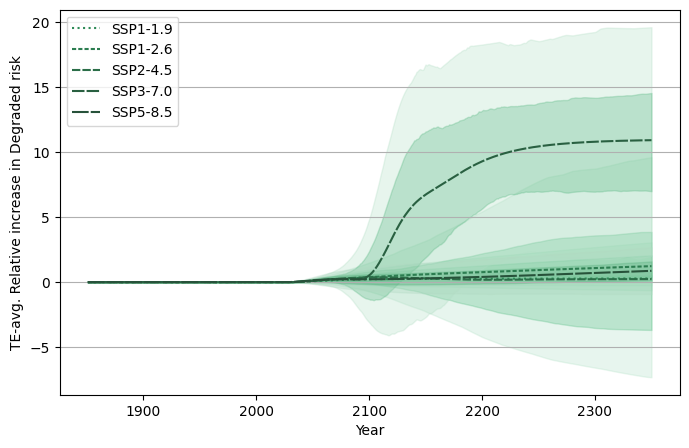

In [60]:
fig,ax = plt.subplots(figsize=(8,5))
theme_col = 'seagreen'

# rel = (D_theory - D_theory_noint)/D_theory_noint
# rel_mean = rel.mean(axis=(0,2)) # averaged over samples and over TEs
# rel_5 = np.quantile(rel,0.05,axis=0).mean(axis=-1)
# rel_25= np.quantile(rel,0.25,axis=0).mean(axis=-1)
# rel_75= np.quantile(rel,0.75,axis=0).mean(axis=-1)
# rel_95= np.quantile(rel,0.95,axis=0).mean(axis=-1)
colors = sns.dark_palette("seagreen",len(scenarios)+2)[::-1]
linestyles = [':'] + [(0,(2*j+2,1)) for j in range(len(scenarios)-2)] + ['-']
scen_labels = ['SSP1-1.9', 'SSP1-2.6', 'SSP2-4.5', 'SSP3-7.0', 'SSP5-8.5']
for i in range(5):
    # theme_col=colors[i]
    ax.plot(years,rel_mean[i,:],
            color=colors[i],ls=linestyles[i],label=scen_labels[i])#,label='Mean')
    ax.fill_between(years, rel_5[i,:], rel_95[i,:],
                     color=util.lighten_color(colors[i],0.3),
                     edgecolor=util.lighten_color(colors[i],0.3),
                     alpha=0.3)#,label='$(P_5,P_{95})$')
    ax.fill_between(years, rel_25[i,:], rel_75[i,:],
                     color=util.lighten_color(colors[i],0.65),
                     edgecolor=util.lighten_color(colors[i],0.65),
                     alpha=0.3)#,label='$(P_{25},P_{75})$')

ax.grid(axis='y')
ylim=ax.axes.get_ylim()

# for t in T_lim_unique:
#     if rel_mean[np.argmin(np.abs(T-t))]<np.mean(ylim):
#         locs = (t,(rel_mean[np.argmin(np.abs(T-t))]+ylim[1])/2)
#     else:
#         locs = (t,(rel_mean[np.argmin(np.abs(T-t))]+ylim[0])/2)
#     ax.plot([t]*2,ylim,ls='-',c='r',zorder=0,lw=1)
#     ax.annotate(' ' + ', '.join(TEs_by_tlim[t]), locs,
#                 ha='left',
#                 va='center',
#                 fontsize=8,
#                 bbox=dict(fc='white',edgecolor='none',boxstyle='round',alpha=0.7),rotation=90)
# ax.plot([T[np.argmax(rel_mean)]]*2,ylim,'k--',lw=0.8)

ax.set_ylim(ylim)
# ax.set_xlim([0,10])
# ax.set_xticks([0,1.257,2,4,6,8,10])
ax.set_ylabel('TE-avg. Relative increase in Degraded risk')
ax.set_xlabel('Year')

# lines = [Line2D([0], [0], color='k', lw=2, label='Mean'),
#          Patch(facecolor=util.lighten_color('k',0.3), 
#                edgecolor=util.lighten_color('k',0.3), label='$(P_5,P_{95})$'),
#          Patch(facecolor=util.lighten_color('k',0.65), 
#                edgecolor=util.lighten_color('k',0.65), label='$(P_{25},P_{75})$')]+[Line2D([0], [0], color=colors[j], lw=2, 
#                  label=scen_labels[j][3:], 
#                 ls = '-') 
#          for j in range(6)]
# lines = lines[::3] + lines[1::3] + lines[2::3]
legend=plt.legend(loc='upper left')

# Stochastic Markov Chains

In [188]:
MC_samples = 50
len_sample = 50
ref_random = np.random.rand(MC_samples,len(TEs),T)
D = np.zeros((MC_samples,len(scenarios),len_sample,len(TEs),T))
for k in tqdm.tqdm(range(MC_samples)):
    for r in (range(len_sample)):
        for j in range(len(scenarios)):
            for t in range(1,T):
                D[k,j,r,:,t] = np.int8(util.environmental_update(D[k,j,r,:,t-1],A[r],p_c=p_c[j,t,:],p_r=p_r) >= ref_random[k,:,t])

100%|███████████████████████████████████████████| 50/50 [03:23<00:00,  4.07s/it]


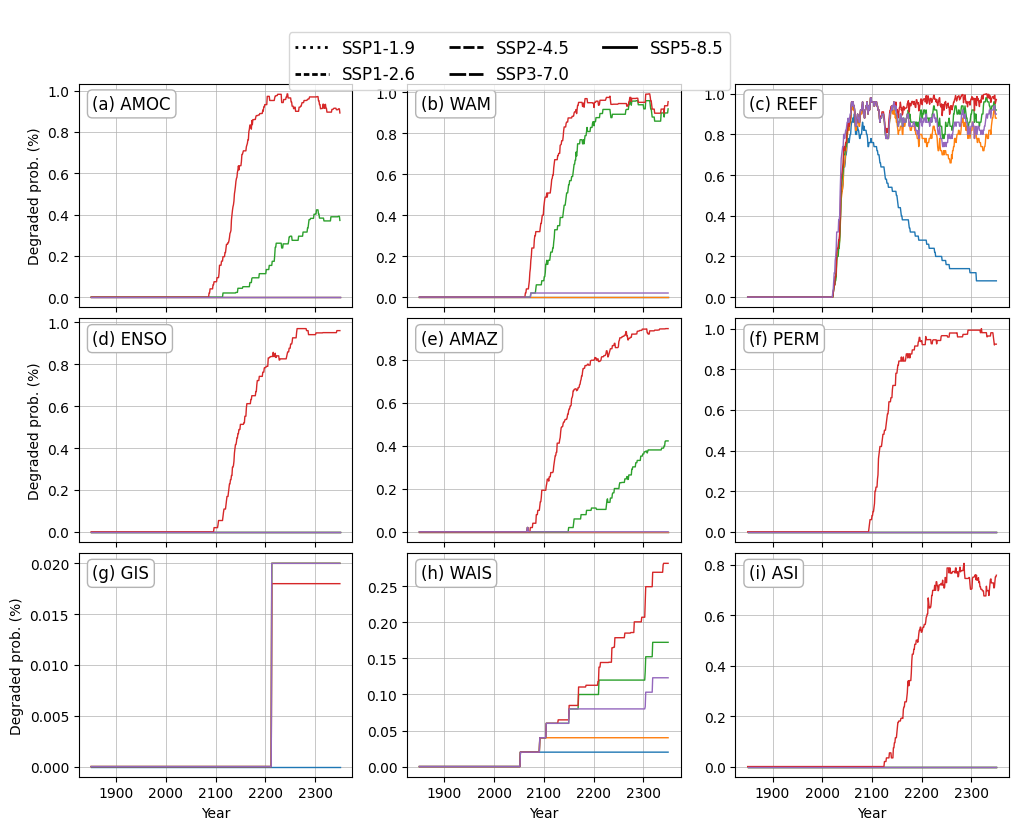

In [189]:
fig,axs = plt.subplots(figsize=(12,9),nrows=3,ncols=3,sharex=True,sharey=False)
fig.subplots_adjust(hspace=0.05) # hspace=0.05

prop_cycle = plt.rcParams['axes.prop_cycle']
colors = prop_cycle.by_key()['color']
linestyles = [':'] + [(0,(2*j+2,1)) for j in range(len(scenarios)-2)] + ['-']
scen_labels = ['SSP1-1.9', 'SSP1-2.6', 'SSP2-4.5', 'SSP3-7.0', 'SSP5-8.5']

TE_ordered = ['AMOC', 'WAM', 'REEF',
              'ENSO', 'AMAZ','PERM',
              'GIS', 'WAIS', 'ASI']
letters = ['(%s)'%l for l in 'abcdefghi']
TE_ind = {te:i for i,te in enumerate(TEs)}
for i_ax,te in enumerate(TE_ordered):
    i = TE_ind[te]
    axs[i_ax//3,i_ax%3].annotate(letters[i_ax] + ' '+ TEs[i],(0.05,0.95),
                                 xycoords='axes fraction',ha='left',va='top',fontsize=12,
                                 bbox=dict(fc='white',edgecolor='0.7',boxstyle='round'))
    # axs[i_ax//3,i_ax%3].plot(years[:D_hist.shape[-1]],D_hist[i,:,:].mean(axis=0)*100,
    #                    c=util.lighten_color(colors[i],0.65), 
    #                    ls='-',lw=1)
    axs[i_ax//3,i_ax%3].grid(visible=True,lw=0.5,axis='both')
    for j in range(len(scenarios)):
        axs[i_ax//3,i_ax%3].plot(years,D[:,j,:,i,:].mean(axis=0).mean(axis=0),
                           c=colors[j],# ls=linestyles[j],
                           lw=1)
    # for k in range(MC_samples):
    #     axs[i_ax//3,i_ax%3].plot(years,D[k,-1,:,i,:].mean(axis=0)*100,
    #                        c=colors[j],# ls=linestyles[j],
    #                        lw=0.1)

# lines=[Line2D([0], [0], color='k', lw=2, label='Historical')] 
lines = [Line2D([0], [0], color=util.lighten_color('k',1),#0.1+(j+3)/(len(scenarios)+3)), 
                lw=2, 
                label=scen_labels[j], 
                ls = linestyles[j]) 
         for j in range(5)]

for i in range(3):
    axs[-1,i].set_xlabel('Year')
    axs[i,0].set_ylabel('Degraded prob. (%)')

fig.legend(handles=lines,ncols=3,loc='upper center',
           prop={'size':12},borderaxespad=2)
# fig.savefig(folder_out+'SSPs.pdf',format='pdf',dpi=300,bbox_inches='tight')

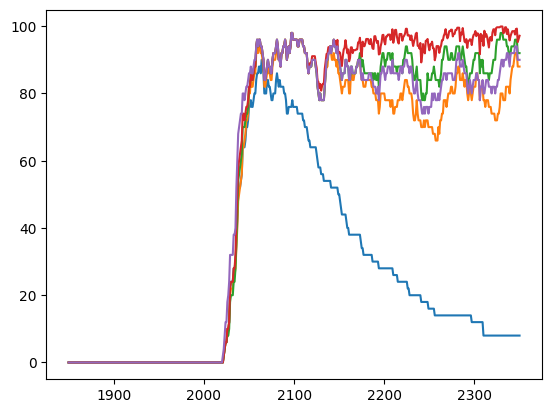

In [190]:
# for k in range(MC_samples):
#     plt.plot(years,D[k,-1,0,i,:],lw=0.2,c='k')

for j in range(len(scenarios)):
    plt.plot(years,D[:,j,:,TE_ind['REEF'],:].mean(axis=0).mean(axis=0)*100)

In [162]:
D.shape

(100, 5, 500, 9, 501)

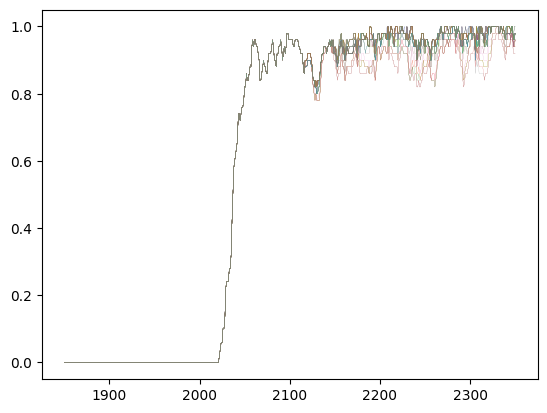

In [193]:
for r in range(len_sample): 
    plt.plot(years,D[:,-2,r,TE_ind['REEF'],:].mean(axis=0),lw=0.1)

In [187]:
np.sum(D[:,-2,:,TE_ind['REEF'],:].mean(axis=0)[:,-1] > 0)
# np.size(D[:,-2,:,TE_ind['REEF'],:].mean(axis=0)[:,-1])

10

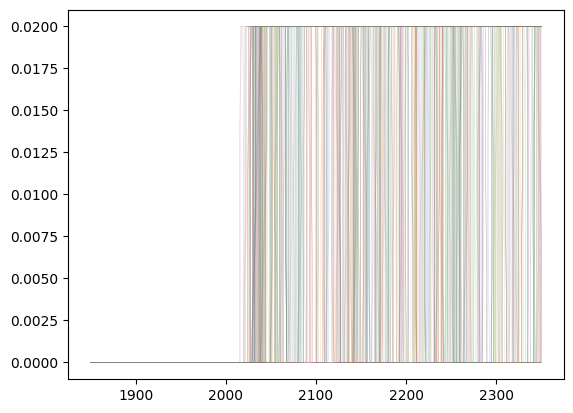

In [179]:
for mc in range(100):
    plt.plot(years,D[mc,-1,:,TE_ind['REEF'],:].mean(axis=0),lw=0.1)

# Pointwise impacts on GWL

In [31]:
df_AM22['Max. Impact** (°C) - Global']

AMAZ    Partial Dieback: 30 GtC / 0.1°CTotal Dieback: ...
AMOC                                                 -0.5
ASI                                                   0.6
ENSO                                                  NaN
GIS                                                  0.13
PERM               125-250 GtC / 175-350 GtCe / 0.2-0.4°C
REEF                                                    ~
WAIS                                                 0.05
WAM                                                     ~
Name: Max. Impact** (°C) - Global, dtype: object

In [78]:
tempimpacts = df_AM22['Max. Impact** (°C) - Global'].to_dict()
# Manually translating the excel entries into numbers
tempimpacts['AMAZ'] = 0.2 # 0.1 at partial dieback, 0.2 at total
tempimpacts['ENSO'] = 0 # NA
tempimpacts['PERM'] = 0.3 # the range is 0.2-0.4
tempimpacts['REEF'] = 0
tempimpacts['WAM'] = 0

df_AM22['DegradedImpact'] = tempimpacts
D_to_T = df_AM22['DegradedImpact'].to_numpy()

In [79]:
D_noint.shape

(6, 9, 501)

In [80]:
T_impacts = np.zeros_like(D)
T_impacts_noint = np.zeros_like(D_noint)
for s in range(len(scenarios)):
    for t in range(501):
        T_impacts_noint[s,:,t] = D_noint[s,:,t]*D_to_T
        for r in range(500):
            T_impacts[s,r,:,t] = D[s,r,:,t]*D_to_T

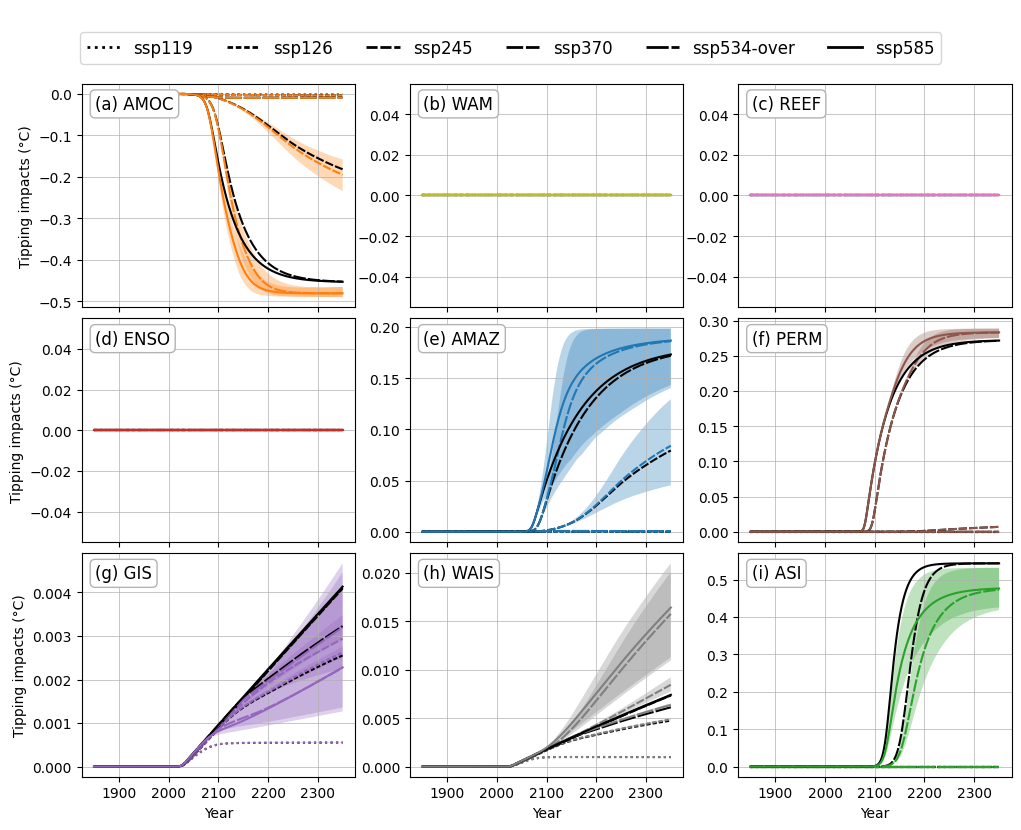

In [81]:
years = np.arange(1850, 2351) 

fig,axs = plt.subplots(figsize=(12,9),nrows=3,ncols=3,sharex=True,sharey=False)
fig.subplots_adjust(hspace=0.05) # hspace=0.05

prop_cycle = plt.rcParams['axes.prop_cycle']
colors = prop_cycle.by_key()['color']
# linestyles = [':',(0, (3, 1, 1, 1, 1, 1)),'-.','--', (2,(10,3)) ,(5,(10,3))]
# scen_labels = ['SSP1-1.9', 'SSP1-2.6', 'SSP2-4.5', 'SSP3-7.0', 'SSP5-3.4-over', 'SSP5-8.5']

# linestyles = [':',(0, (3, 1, 1, 1, 1, 1)),'-.','--',(5,(10,3))]
linestyles = [':'] + [(0,(2*j+2,1)) for j in range(len(scenarios)-2)] + ['-']
scen_labels = ['SSP1-1.9', 'SSP1-2.6', 'SSP2-4.5', 'SSP3-7.0', 'SSP5-8.5']
if len(scen_labels) != len(scenarios):
    scen_labels = scenarios

TE_ordered = ['AMOC', 'WAM', 'REEF',
              'ENSO', 'AMAZ','PERM',
              'GIS', 'WAIS', 'ASI']
letters = ['(%s)'%l for l in 'abcdefghi']
TE_ind = {te:i for i,te in enumerate(TEs)}
for i_ax,te in enumerate(TE_ordered):
    i = TE_ind[te]
    axs[i_ax//3,i_ax%3].annotate(letters[i_ax] + ' '+ TEs[i],(0.05,0.95),
                                 xycoords='axes fraction',ha='left',va='top',fontsize=12,
                                 bbox=dict(fc='white',edgecolor='0.7',boxstyle='round'))
    axs[i_ax//3,i_ax%3].grid(visible=True,lw=0.5,axis='both')
    for j in range(len(scenarios)):
        axs[i_ax//3,i_ax%3].plot(years,(T_impacts_noint[j,i,:]),
                                 c='k',#0.1+(j+3)/(len(scenarios)+3)), 
                                 ls=linestyles[j],
                                 lw=1.5)
        axs[i_ax//3,i_ax%3].plot(years,(T_impacts[j,:,i,:].mean(axis=0)),
                                 c=util.lighten_color(colors[i],1),#0.1+(j+3)/(len(scenarios)+3)), 
                                 ls=linestyles[j],
                                 lw=1.5)
        axs[i_ax//3,i_ax%3].fill_between(years,
                                         (np.quantile(T_impacts[j,:,i,:],0.05,axis=0)),
                                         (np.quantile(T_impacts[j,:,i,:],0.95,axis=0)),
                                         color=util.lighten_color(colors[i],1),#0.1+(j+3)/(len(scenarios)+3)), 
                                         alpha=0.3,
                                         lw=1,edgecolor='none')
        
lines = [Line2D([0], [0], color=util.lighten_color('k',1),#0.1+(j+3)/(len(scenarios)+3)), 
                lw=2, 
                label=scen_labels[j], 
                ls = linestyles[j]) 
         for j in range(len(scenarios))]

for i in range(3):
    axs[-1,i].set_xlabel('Year')
    axs[i,0].set_ylabel('Tipping impacts (°C)')

fig.legend(handles=lines,ncols=len(scenarios),loc='upper center',
           prop={'size':12},borderaxespad=2)
# fig.savefig(folder_out+'extendedSSPs_int_diff.pdf',format='pdf',dpi=300,bbox_inches='tight')

In [62]:
T_impacts_noint.shape

(6, 9, 501)

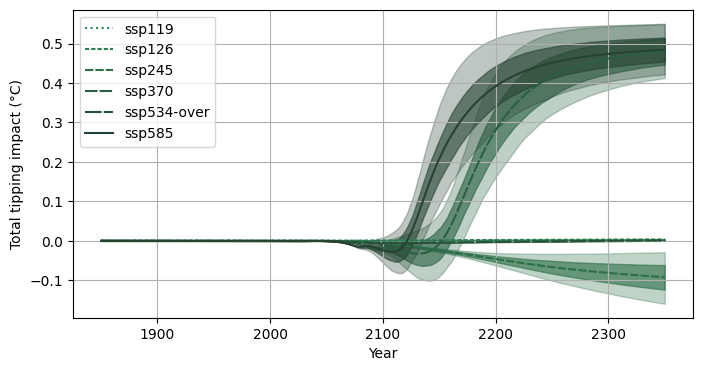

In [84]:
fig,ax = plt.subplots(figsize=(8,4))
theme_col = 'k'
colors = sns.dark_palette("seagreen",len(scenarios)+2)[::-1]
linestyles = [':'] + [(0,(2*j+2,1)) for j in range(len(scenarios)-2)] + ['-']
scen_labels = ['SSP1-1.9', 'SSP1-2.6', 'SSP2-4.5', 'SSP3-7.0', 'SSP5-8.5']
if len(scen_labels) != len(scenarios):
    scen_labels = scenarios
years=np.arange(1850,2351)
for j in range(len(scenarios)):
    # ax.plot(years,dfs[scenarios[j]]['mean'].to_numpy(),
    #     color='r',label=scen_labels[j],ls=linestyles[j])
    shift = 0#-1*T_impacts_noint[j,:,:].sum(axis=0) #dfs[scenarios[j]]['mean'].to_numpy()
    ax.fill_between(years, 
                    np.quantile(T_impacts[j,:,:,:].sum(axis=1),0.05,axis=0) +shift,
                    np.quantile(T_impacts[j,:,:,:].sum(axis=1),0.95,axis=0) +shift,
                    # lighten_color by 0.3
                    color=util.lighten_color(colors[j],1),
                    edgecolor=util.lighten_color(colors[j],1), 
                    alpha=0.3)
    ax.fill_between(years, 
                 np.quantile(T_impacts[j,:,:,:].sum(axis=1),0.25,axis=0) +shift,
                 np.quantile(T_impacts[j,:,:,:].sum(axis=1),0.75,axis=0) +shift,
                    # lighten_color by 0.65
                 color=util.lighten_color(colors[j],1),
                 edgecolor=util.lighten_color(colors[j],1),
                 alpha=0.6)
    # ax.plot(years,T_impacts_noint[j,:,:].sum(axis=0) +shift,
    #     color='k',ls=linestyles[j])
    ax.plot(years,T_impacts[j,:,:,:].sum(axis=1).mean(axis=0) +shift,
        color=util.lighten_color(colors[j],1),ls=linestyles[j],label=scen_labels[j],lw=1.5)
    # ax.plot(years,D_noint[j,:,:].sum(axis=0),
    #                          c=util.lighten_color(colors[j],1), 
    #                          ls='--',lw=1)

ax.grid()
# ax.set_xlim([1850,2350])
ax.set_ylabel('Total tipping impact (°C)')
ax.set_xlabel('Year')

# ax_temp = ax.inset_axes([1850, 1, 170, 3.5], transform=ax.transData)
# ax_temp.yaxis.tick_right()
# ax_temp.set_xlim([1850,2350])
# ax_temp.set_xticks([1900,2100,2300])
# ax_temp.tick_params(axis='both', which='major', labelsize=8)
# for j,s in enumerate(scenarios):
#     # ax_temp.fill_between(years, dfs[s][0.05],dfs[s][0.95],alpha=0.1,color=colors[i])
#     ax_temp.plot(years,dfs[s]['mean'].to_numpy(), color=colors[j])

legend=plt.legend(loc='upper left',ncols=1)
# fig.savefig(folder_out+'ES_extendedSSPs.pdf',format='pdf',dpi=300,bbox_inches='tight')

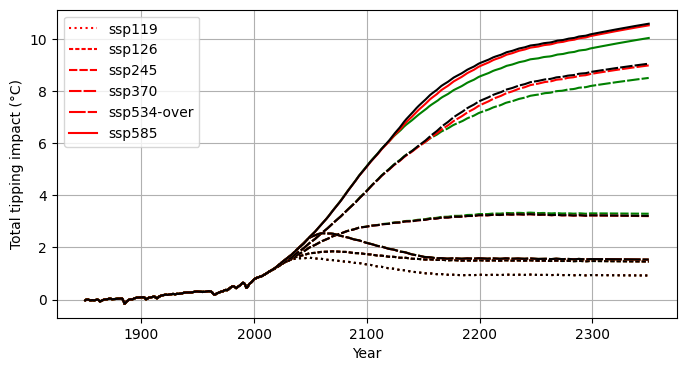

In [88]:
fig,ax = plt.subplots(figsize=(8,4))
theme_col = 'k'
colors = sns.dark_palette("seagreen",len(scenarios)+2)[::-1]
linestyles = [':'] + [(0,(2*j+2,1)) for j in range(len(scenarios)-2)] + ['-']
scen_labels = ['SSP1-1.9', 'SSP1-2.6', 'SSP2-4.5', 'SSP3-7.0', 'SSP5-8.5']
if len(scen_labels) != len(scenarios):
    scen_labels = scenarios
years=np.arange(1850,2351)
for j in range(len(scenarios)):
    # ax.plot(years,dfs[scenarios[j]]['mean'].to_numpy(),
    #     color='r',label=scen_labels[j],ls=linestyles[j])
    shift = dfs[scenarios[j]]['mean'].to_numpy()
    ax.plot(years,shift,color='g',ls=linestyles[j])
    ax.plot(years,T_impacts[j,:,:,:].sum(axis=1).mean(axis=0) +shift,
        color='r',ls=linestyles[j],label=scen_labels[j],lw=1.5)
    ax.plot(years,T_impacts_noint[j,:,:].sum(axis=0) +shift,
        color='k',ls=linestyles[j])
    # ax.plot(years,D_noint[j,:,:].sum(axis=0),
    #                          c=util.lighten_color(colors[j],1), 
    #                          ls='--',lw=1)

ax.grid()
# ax.set_xlim([1850,2350])
ax.set_ylabel('Total tipping impact (°C)')
ax.set_xlabel('Year')

# ax_temp = ax.inset_axes([1850, 1, 170, 3.5], transform=ax.transData)
# ax_temp.yaxis.tick_right()
# ax_temp.set_xlim([1850,2350])
# ax_temp.set_xticks([1900,2100,2300])
# ax_temp.tick_params(axis='both', which='major', labelsize=8)
# for j,s in enumerate(scenarios):
#     # ax_temp.fill_between(years, dfs[s][0.05],dfs[s][0.95],alpha=0.1,color=colors[i])
#     ax_temp.plot(years,dfs[s]['mean'].to_numpy(), color=colors[j])

legend=plt.legend(loc='upper left',ncols=1)
# fig.savefig(folder_out+'ES_extendedSSPs.pdf',format='pdf',dpi=300,bbox_inches='tight')

# Feedbacks between risk and GWL

In [108]:
df = pd.read_excel('../Data/AR6WG1Fig440_tempseries (1).xlsx')
scenarios = df['scenario'].unique()

dfs = {s: df[df['scenario']==s].set_index('quantile').iloc[:,9:].transpose() for s in scenarios}

years = np.arange(1850, 2351) 
len_sample=500
T = len(years)
T_2014 = 165
# GMST_hist = df_SSPs['Historical']['Mean'].to_numpy()

p_c_h = np.ones((165,len(df_AM22))) # 1850-2014 inclusive
p_c_h *= 1/(df_AM22['CollapseTime'].to_numpy()+1)

p_c = np.ones((len(scenarios),T-165,len(df_AM22)))
p_c *= 1/(df_AM22['CollapseTime'].to_numpy()+1)
# for t in range(len(GMST_hist)):
#     p_c[:,t,:] *= logistic(GMST_hist[t],T_lim,betas)
for t in range(165):
    p_c_h[t,:] *= logistic(dfs[scenarios[0]]['mean'].to_numpy()[t],T_lim,betas)

# for t in range(165,T):
#     for i,s in enumerate(scenarios):
#         p_c[i,t-165,:] *= logistic(dfs[s]['mean'].to_numpy()[t], T_lim, betas)

In [122]:
D = np.zeros((len(scenarios),len_sample,len(TEs),T))
temp = np.zeros((len(scenarios),len_sample,T))
for j,s in enumerate(scenarios):
    temp[j,:,:] = dfs[s]['mean'].to_numpy()

for r in tqdm.tqdm(range(len_sample)):
    for t in range(1,T_2014):
        D[0,r,:,t] = util.environmental_update(D[0,r,:,t-1],A[r],p_c=p_c_h[t,:],p_r=p_r)
        D[:,r,:,t] = D[0,r,:,t]
    for j in range(len(scenarios)):
        for t in range(T_2014,T):
            temp[j,r,t] += np.dot(D[j,r,:,t-1], D_to_T)
            D[j,r,:,t] = util.environmental_update(D[j,r,:,t-1],A[r],
                                                   p_c=logistic(temp[j,r,t],T_lim,betas)/(df_AM22['CollapseTime'].to_numpy()+1),
                                                   p_r=p_r)

D_noint = np.zeros((len(scenarios),len(TEs),T))
temp_noint = np.zeros((len(scenarios),T))
for j,s in enumerate(scenarios):
    temp_noint[j,:] = dfs[s]['mean'].to_numpy()

for t in tqdm.tqdm(range(1,T_2014)):
    D_noint[0,:,t] = util.environmental_update(D_noint[0,:,t-1],
                                               np.zeros((len(TEs),len(TEs))),
                                               p_c=p_c_h[t,:],p_r=p_r)
    D_noint[:,:,t] = D_noint[0,:,t]
for t in tqdm.tqdm(range(T_2014,T)):
    for j in range(len(scenarios)):
        temp_noint[j,t] += np.dot(D_noint[j,:,t-1], D_to_T)
        D_noint[j,:,t] = util.environmental_update(D_noint[j,:,t-1],
                                                   np.zeros((len(TEs),len(TEs))),
                                                   p_c=logistic(temp_noint[j,t],T_lim,betas)/(df_AM22['CollapseTime'].to_numpy()+1),
                                                   p_r=p_r)

100%|███████████████████████████████████████| 336/336 [00:00<00:00, 3320.62it/s]


In [110]:
np.shape(D)

(9,)

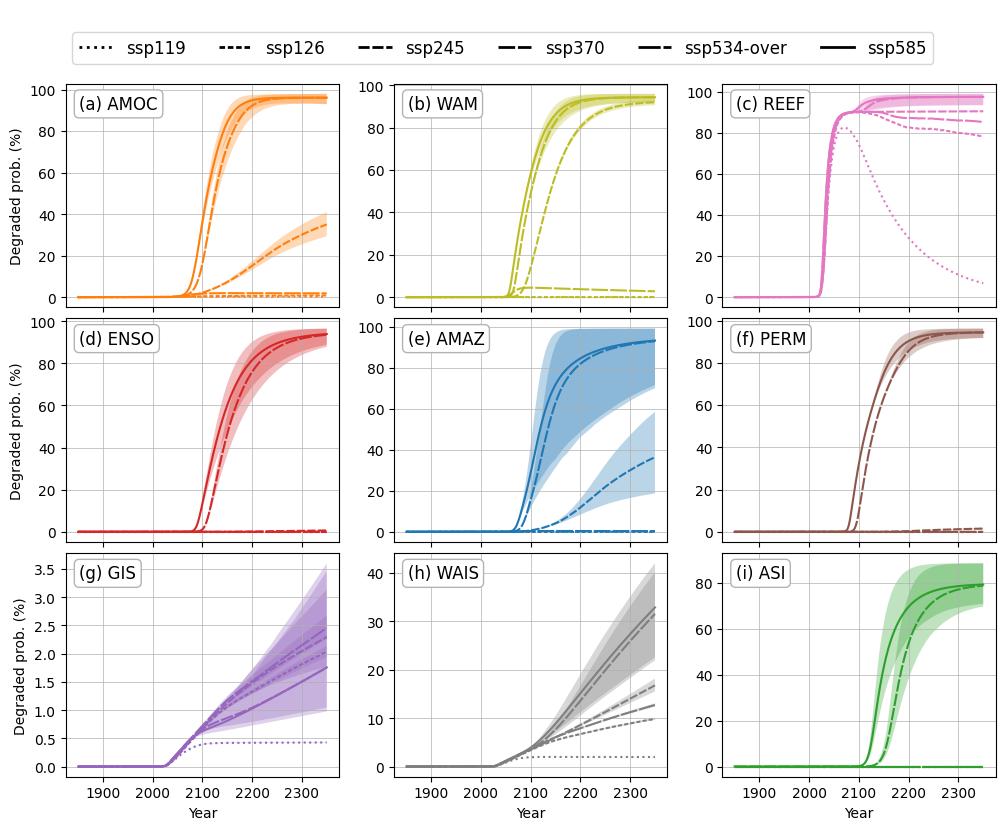

In [123]:
years = np.arange(1850, 2351) 

fig,axs = plt.subplots(figsize=(12,9),nrows=3,ncols=3,sharex=True,sharey=False)
fig.subplots_adjust(hspace=0.05) # hspace=0.05

prop_cycle = plt.rcParams['axes.prop_cycle']
colors = prop_cycle.by_key()['color']
# linestyles = [':',(0, (3, 1, 1, 1, 1, 1)),'-.','--', (2,(10,3)) ,(5,(10,3))]
# scen_labels = ['SSP1-1.9', 'SSP1-2.6', 'SSP2-4.5', 'SSP3-7.0', 'SSP5-3.4-over', 'SSP5-8.5']

# linestyles = [':',(0, (3, 1, 1, 1, 1, 1)),'-.','--',(5,(10,3))]
linestyles = [':'] + [(0,(2*j+2,1)) for j in range(len(scenarios)-2)] + ['-']
scen_labels = ['SSP1-1.9', 'SSP1-2.6', 'SSP2-4.5', 'SSP3-7.0', 'SSP5-8.5']
if len(scen_labels) != len(scenarios):
    scen_labels = scenarios

TE_ordered = ['AMOC', 'WAM', 'REEF',
              'ENSO', 'AMAZ','PERM',
              'GIS', 'WAIS', 'ASI']
letters = ['(%s)'%l for l in 'abcdefghi']
TE_ind = {te:i for i,te in enumerate(TEs)}
for i_ax,te in enumerate(TE_ordered):
    i = TE_ind[te]
    axs[i_ax//3,i_ax%3].annotate(letters[i_ax] + ' '+ TEs[i],(0.05,0.95),
                                 xycoords='axes fraction',ha='left',va='top',fontsize=12,
                                 bbox=dict(fc='white',edgecolor='0.7',boxstyle='round'))
    # axs[i_ax//3,i_ax%3].plot(years[:D_hist.shape[-1]],D_hist[i,:,:].mean(axis=0)*100,
    #                    c=util.lighten_color(colors[i],0.65), 
    #                    ls='-',lw=1)
    axs[i_ax//3,i_ax%3].grid(visible=True,lw=0.5,axis='both')
    for j in range(len(scenarios)):
        axs[i_ax//3,i_ax%3].plot(years,D[j,:,i,:].mean(axis=0)*100,
                                 c=util.lighten_color(colors[i],1),#0.1+(j+3)/(len(scenarios)+3)), 
                                 ls=linestyles[j],
                                 lw=1.5)
        # axs[i_ax//3,i_ax%3].plot(years,D_noint[j,i,:]*100,color='k',lw=0.5)
        # axs[i_ax//3,i_ax%3].plot(years,D[j,:,i,:].mean(axis=0)*100,
        #                          c=colors[i], ls=linestyles[j],
        #                          lw=1)
        axs[i_ax//3,i_ax%3].fill_between(years,
                                         np.quantile(D[j,:,i,:],0.05,axis=0)*100,
                                         np.quantile(D[j,:,i,:],0.95,axis=0)*100,
                                         color=util.lighten_color(colors[i],1),#0.1+(j+3)/(len(scenarios)+3)), 
                                         alpha=0.3,
                                         lw=1,edgecolor='none')

# lines=[Line2D([0], [0], color='k', lw=2, label='Historical')] 
lines = [Line2D([0], [0], color=util.lighten_color('k',1),#0.1+(j+3)/(len(scenarios)+3)), 
                lw=2, 
                label=scen_labels[j], 
                ls = linestyles[j]) 
         for j in range(len(scenarios))]

for i in range(3):
    axs[-1,i].set_xlabel('Year')
    axs[i,0].set_ylabel('Degraded prob. (%)')

# axs[0,0].set_xlim([1850,2015])
# axs[0,0].set_ylim([0,10])

fig.legend(handles=lines,ncols=len(scenarios),loc='upper center',
           prop={'size':12},borderaxespad=2)

In [133]:
temp.shape

(6, 500, 501)

In [134]:
fig,ax = plt.subplots(figsize=(8,4))
theme_col = 'k'
colors = sns.dark_palette("seagreen",len(scenarios)+2)[::-1]
linestyles = [':'] + [(0,(2*j+2,1)) for j in range(len(scenarios)-2)] + ['-']
scen_labels = ['SSP1-1.9', 'SSP1-2.6', 'SSP2-4.5', 'SSP3-7.0', 'SSP5-8.5']
if len(scen_labels) != len(scenarios):
    scen_labels = scenarios
years=np.arange(1850,2351)
for j in range(len(scenarios)):
    # ax.plot(years,dfs[scenarios[j]]['mean'].to_numpy(),
    #     color='r',label=scen_labels[j],ls=linestyles[j])
    shift = -dfs[scenarios[j]]['mean'].to_numpy()
    ax.fill_between(years, 
                    np.quantile(temp[j,:,:],0.05,axis=0) +shift,
                    np.quantile(temp[j,:,:],0.95,axis=0) +shift,
                    # lighten_color by 0.3
                    color=util.lighten_color(colors[j],1),
                    edgecolor=util.lighten_color(colors[j],1), 
                    alpha=0.3)
    ax.fill_between(years, 
                 np.quantile(temp[j,:,:],0.25,axis=0) +shift,
                 np.quantile(temp[j,:,:],0.75,axis=0) +shift,
                    # lighten_color by 0.65
                 color=util.lighten_color(colors[j],1),
                 edgecolor=util.lighten_color(colors[j],1),
                 alpha=0.6)
    # ax.plot(years,T_impacts_noint[j,:,:].sum(axis=0) +shift,
    #     color='k',ls=linestyles[j])
    ax.plot(years,temp[j,:,:].mean(axis=0) +shift,
        color=util.lighten_color(colors[j],1),ls=linestyles[j],label=scen_labels[j],lw=1.5)
    # ax.plot(years,D_noint[j,:,:].sum(axis=0),
    #                          c=util.lighten_color(colors[j],1), 
    #                          ls='--',lw=1)

for j,s in enumerate(scenarios):
    ax.annotate(s,(2350,temp[j,:,-1].mean(axis=0)+shift[-1]),
                xycoords='data fraction',ha='left',va='center',fontsize=12,
                bbox=dict(fc='white',edgecolor='0.7',boxstyle='round'))
ax.grid()
# ax.set_xlim([1850,2350])
ax.set_ylabel('Total tipping impact (°C)')
ax.set_xlabel('Year')

# ax_temp = ax.inset_axes([1850, 1, 170, 3.5], transform=ax.transData)
# ax_temp.yaxis.tick_right()
# ax_temp.set_xlim([1850,2350])
# ax_temp.set_xticks([1900,2100,2300])
# ax_temp.tick_params(axis='both', which='major', labelsize=8)
# for j,s in enumerate(scenarios):
#     # ax_temp.fill_between(years, dfs[s][0.05],dfs[s][0.95],alpha=0.1,color=colors[i])
#     ax_temp.plot(years,dfs[s]['mean'].to_numpy(), color=colors[j])

legend=plt.legend(loc='upper left',ncols=1)
# fig.savefig(folder_out+'ES_extendedSSPs.pdf',format='pdf',dpi=300,bbox_inches='tight')

Error in callback <function _draw_all_if_interactive at 0x74a28651f240> (for post_execute), with arguments args (),kwargs {}:


ValueError: 'data fraction' is not a valid coordinate

ValueError: 'data fraction' is not a valid coordinate

<Figure size 800x400 with 1 Axes>